**IMPORTING LIBRARIES**

In [1]:
%matplotlib inline


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.image import imread
import random
import os
from os import listdir
from PIL import Image
import tensorflow as tf
from keras.preprocessing import image
from tensorflow. keras.utils import img_to_array, array_to_img
from keras.optimizers import Adam
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D
from keras.layers import Activation, Flatten, Dropout, Dense
from sklearn. model_selection import train_test_split
from keras.models import model_from_json
from keras.utils import to_categorical

In [3]:
dataset = (r"C:\Users\fastf\Downloads\fruit dataset")

**VISUALIZING THE DATASET**

In [4]:
dataset = tf.keras.utils.image_dataset_from_directory(
    r"C:\Users\fastf\Downloads\fruit dataset",
    image_size=(224, 224),
    batch_size=32)




Found 16264 files belonging to 4 classes.


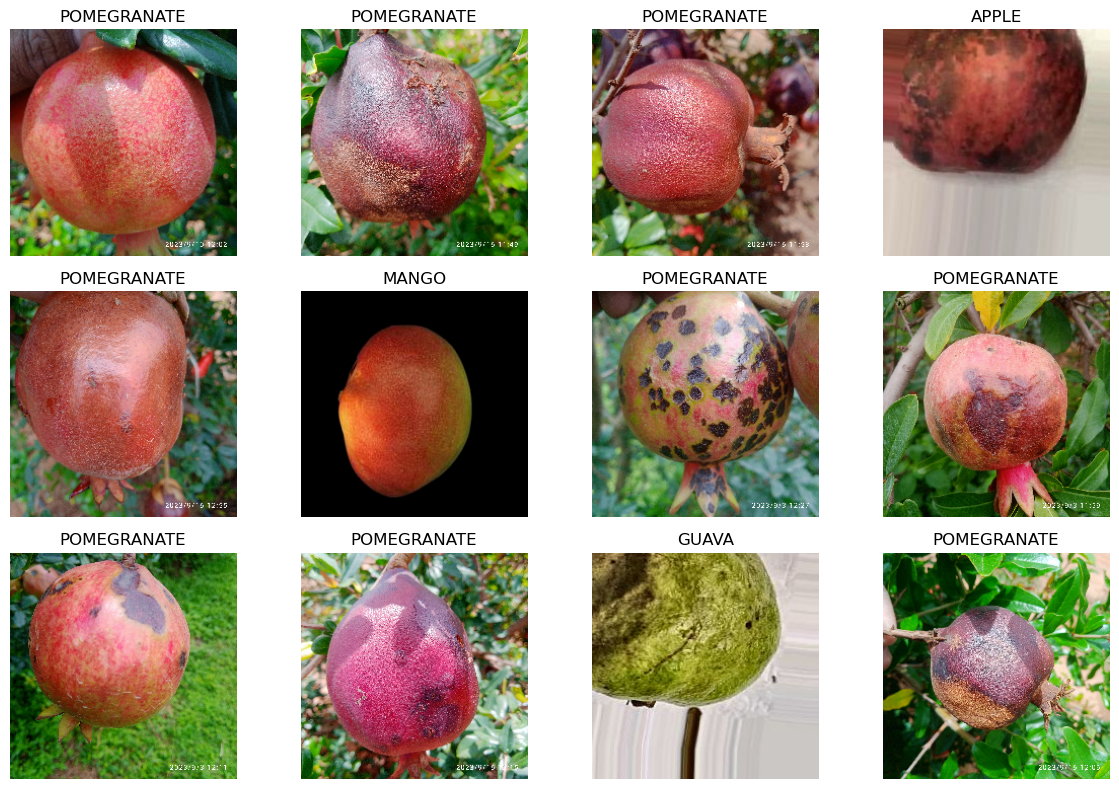

In [5]:
class_names = dataset.class_names

plt.figure(figsize=(12, 8))
for images, labels in dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()


In [6]:
import os
import matplotlib.pyplot as plt
from collections import defaultdict
from PIL import Image

In [7]:
root_dir = "C:/Users/fastf/Downloads/fruit dataset"


fruit_groups = defaultdict(list)

for fruit_folder in os.listdir(root_dir):
    fruit_path = os.path.join(root_dir, fruit_folder)
    if os.path.isdir(fruit_path):
        for class_folder in os.listdir(fruit_path):
            if "_" in class_folder:
                fruit_name = fruit_folder.capitalize()
                fruit_groups[fruit_name].append(os.path.join(fruit_path, class_folder))

In [ ]:
import matplotlib.pyplot as plt
import math
import numpy as np
import warnings


def visualize_all_fruits_with_diseases(
    dataset,
    class_names,
    images_per_fruit=4,
    cols=4,
    normalize=True
):
    """
    Visualize disease samples for each fruit class.

    Args:
        dataset: tf.data.Dataset yielding (images, labels)
        class_names: List mapping label index → class name
        images_per_fruit: Max images to show per fruit
        cols: Number of columns in grid
        normalize: Whether to rescale images to uint8
    """

    if dataset is None or class_names is None:
        raise ValueError("Dataset and class_names must not be None")

    fruit_to_images = {}
    found_any = False

    # -------------------------------
    # Collect Images
    # -------------------------------
    for image_batch, label_batch in dataset:
        for img, label in zip(image_batch, label_batch):
            label_idx = int(label.numpy())
            if label_idx >= len(class_names):
                continue

            label_name = class_names[label_idx].strip()
            parts = label_name.split()

            if len(parts) < 2:
                continue

            fruit = parts[-1]
            disease = " ".join(parts[:-1])

            fruit_to_images.setdefault(fruit, [])

            if len(fruit_to_images[fruit]) < images_per_fruit:
                image_np = img.numpy()

                if normalize:
                    image_np = np.clip(image_np, 0, 255).astype("uint8")

                fruit_to_images[fruit].append((image_np, disease))
                found_any = True

        # Stop early only if all fruits reached limit
        if fruit_to_images and all(
            len(v) >= images_per_fruit for v in fruit_to_images.values()
        ):
            break

    if not found_any:
        warnings.warn("No images found to visualize.")
        return

    # -------------------------------
    # Visualization
    # -------------------------------
    for fruit, images in fruit_to_images.items():
        if not images:
            continue

        num_images = len(images)
        rows = math.ceil(num_images / cols)

        plt.figure(figsize=(cols * 3.5, rows * 3.5))

        for i, (img, disease) in enumerate(images):
            ax = plt.subplot(rows, cols, i + 1)
            ax.imshow(img)
            ax.set_title(
                f"{fruit}\n{disease}",
                fontsize=9,
                pad=4
            )
            ax.axis("off")

        plt.suptitle(
            f"{fruit} — Disease Samples",
            fontsize=15,
            fontweight="bold"
        )
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()


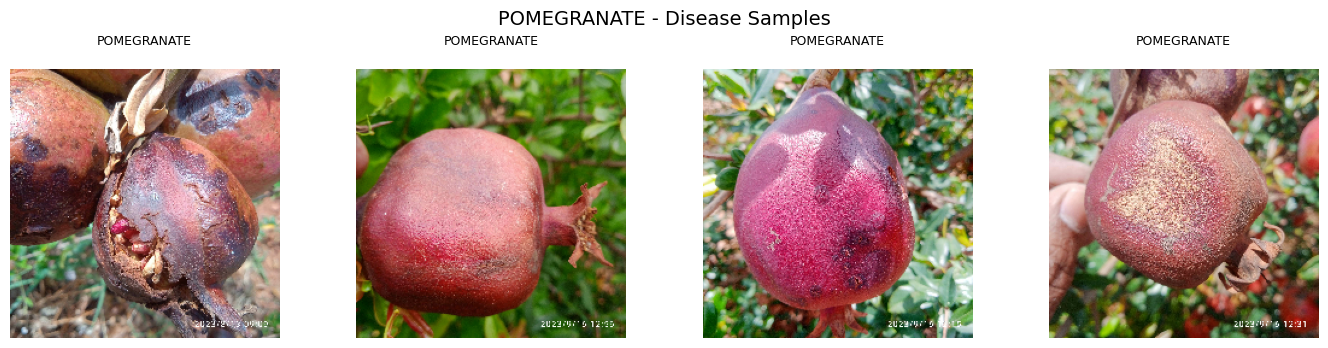

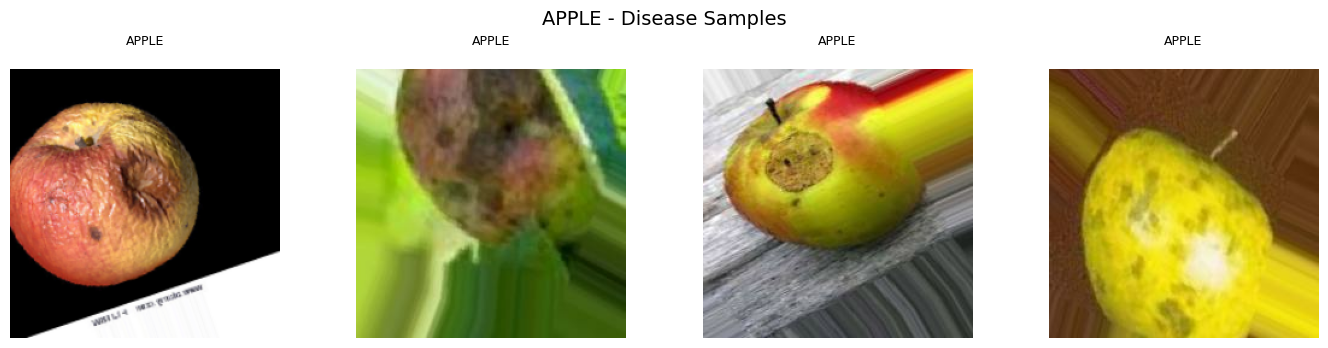

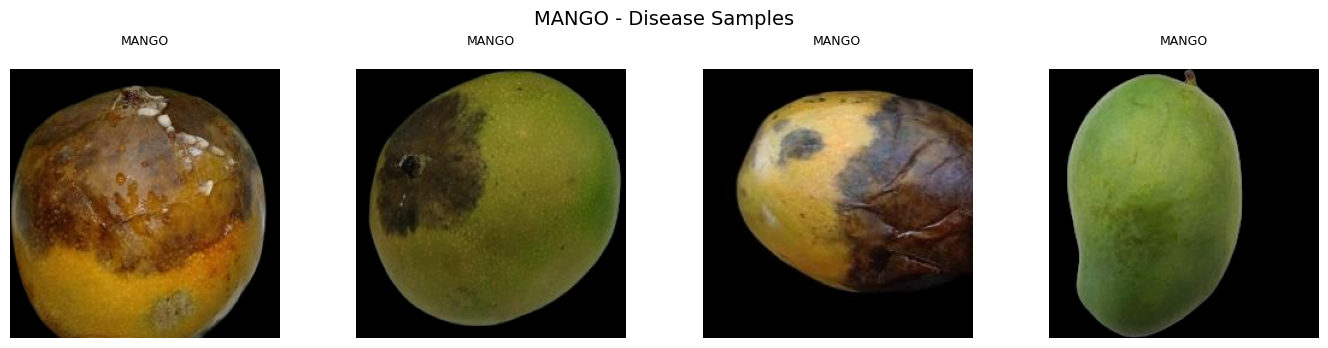

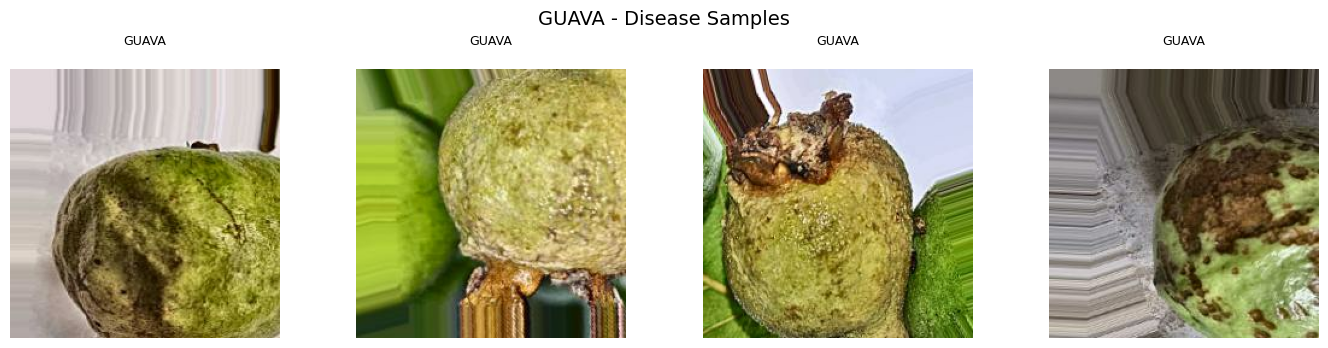

In [9]:
visualize_all_fruits_with_diseases(dataset, class_names, images_per_fruit=4)



**VISUALIZE THE CLASS COUNT AND CHECK THE IMBALANCE**

In [ ]:
import os
from collections import defaultdict
import logging

# -------------------------------
# Logging Configuration
# -------------------------------
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s | %(message)s"
)

# -------------------------------
# Dataset Root
# -------------------------------
root_dir = r"C:\Users\fastf\Downloads\fruit dataset"

if not os.path.exists(root_dir):
    raise FileNotFoundError(f"Dataset path not found: {root_dir}")

# -------------------------------
# Supported Image Formats
# -------------------------------
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

# -------------------------------
# Disease Count Collector
# -------------------------------
disease_counts = defaultdict(int)

for fruit in sorted(os.listdir(root_dir)):
    fruit_path = os.path.join(root_dir, fruit)

    if not os.path.isdir(fruit_path):
        continue

    try:
        for disease in sorted(os.listdir(fruit_path)):
            disease_path = os.path.join(fruit_path, disease)

            if not os.path.isdir(disease_path):
                continue

            try:
                image_count = sum(
                    1 for file in os.listdir(disease_path)
                    if file.lower().endswith(IMAGE_EXTENSIONS)
                )

                disease_name = f"{disease}_{fruit}"
                disease_counts[disease_name] = image_count

            except PermissionError:
                logging.warning(f"Permission denied: {disease_path}")
            except Exception as e:
                logging.warning(f"Error reading {disease_path}: {e}")

    except PermissionError:
        logging.warning(f"Permission denied: {fruit_path}")

# -------------------------------
# Output (Sorted)
# -------------------------------
if not disease_counts:
    logging.warning("No disease images found.")
else:
    print("\n📊 Disease-wise Image Count\n" + "-" * 35)

    for disease, count in sorted(
        disease_counts.items(),
        key=lambda x: x[1],
        reverse=True
    ):
        print(f"{disease:<30} : {count}")

    print("\n📈 Summary")
    print("-" * 35)
    print(f"Total disease classes : {len(disease_counts)}")
    print(f"Total images          : {sum(disease_counts.values())}")
    print(f"Max images in a class : {max(disease_counts.values())}")
    print(f"Min images in a class : {min(disease_counts.values())}")


Blotch_Apple_APPLE: 500
Healthy_Apple_APPLE: 500
Rot_Apple_APPLE: 500
Scab_Apple_APPLE: 500
Anthracnose_Guava_GUAVA: 500
Fruitfly_Guava_GUAVA: 500
Healthy_Guava_GUAVA: 500
Alternaria_Mango_MANGO: 500
Anthracnose_Mango_MANGO: 500
Black Mould Rot (Aspergillus)_Mango_MANGO: 500
Healthy_Mango_MANGO: 205
Stem and Rot (Lasiodiplodia)_MANGO: 499
Alternaria_POMEGRANATE: 886
Anthracnose_POMEGRANATE: 1166
Bacterial_Blight_POMEGRANATE: 966
Cercospora_POMEGRANATE: 631
Healthy_POMEGRANATE: 1450


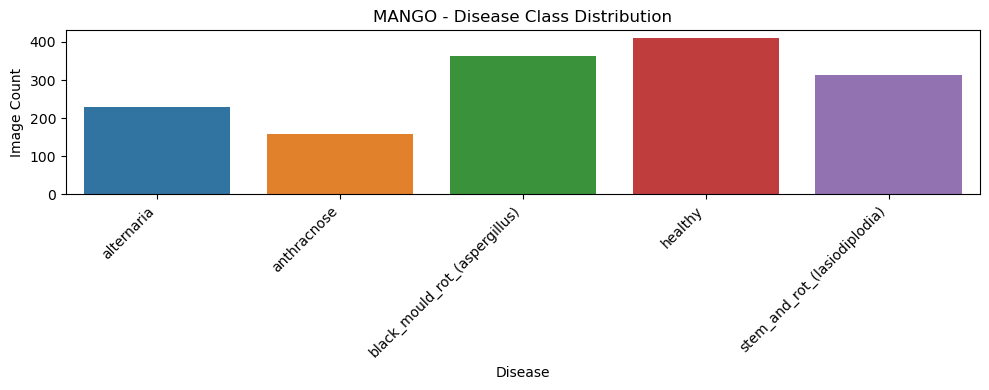

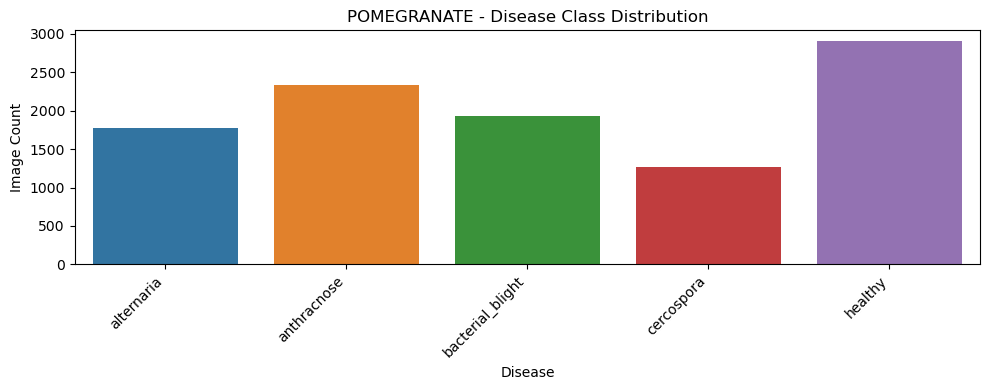

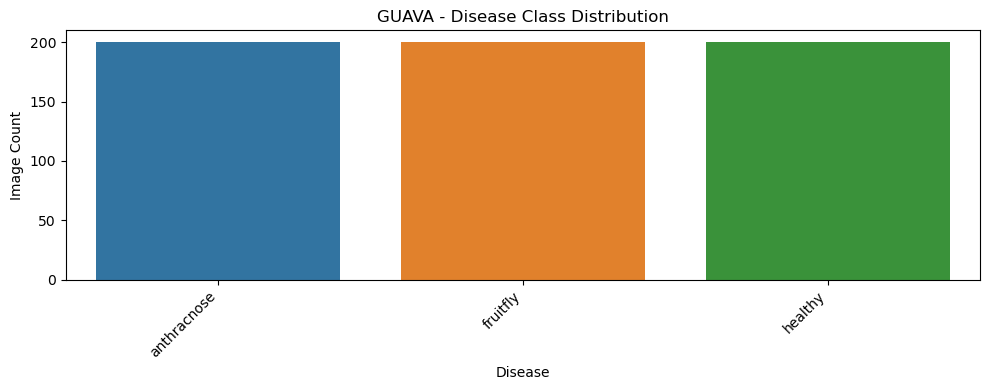

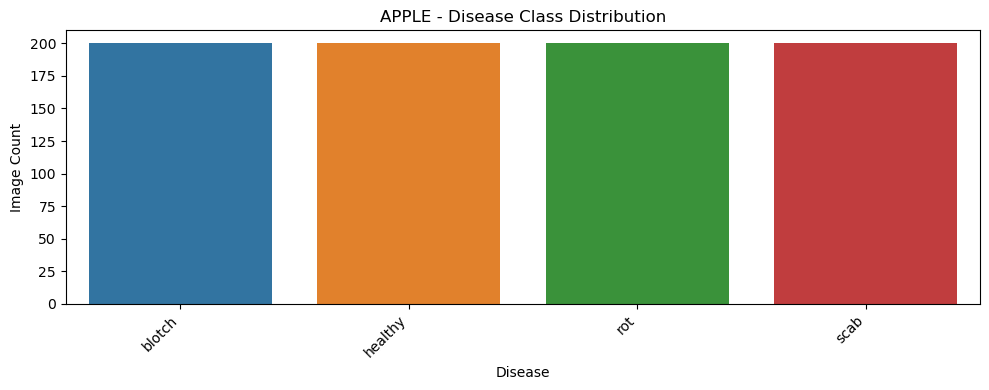

In [ ]:
import os
import matplotlib.pyplot as plt
from collections import defaultdict
import seaborn as sns
import warnings

# -------------------------------
# Dataset Path
# -------------------------------
dataset_dir = r"C:\Users\fastf\Downloads\fruit_dataset_flattened"

if not os.path.exists(dataset_dir):
    raise FileNotFoundError(f"Dataset directory not found: {dataset_dir}")

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

# -------------------------------
# Fruit → Disease → Count
# -------------------------------
fruit_disease_counts = defaultdict(lambda: defaultdict(int))

for class_folder in sorted(os.listdir(dataset_dir)):
    class_path = os.path.join(dataset_dir, class_folder)

    if not os.path.isdir(class_path):
        continue

    # Count only image files
    try:
        image_count = sum(
            1 for f in os.listdir(class_path)
            if f.lower().endswith(IMAGE_EXTENSIONS)
        )
    except Exception:
        warnings.warn(f"Skipping unreadable folder: {class_folder}")
        continue

    if image_count == 0:
        continue

    # -------------------------------
    # Robust Class Name Parsing
    # -------------------------------
    parts = class_folder.lower().split("_")

    if len(parts) < 2:
        continue

    # Handle duplicated fruit names (e.g., apple_apple)
    if len(parts) >= 3 and parts[-1] == parts[-2]:
        fruit = parts[-1].upper()
        disease = "_".join(parts[:-2])
    else:
        fruit = parts[-1].upper()
        disease = "_".join(parts[:-1])

    disease = disease.replace("_", " ").title()

    fruit_disease_counts[fruit][disease] += image_count

# -------------------------------
# Visualization
# -------------------------------
if not fruit_disease_counts:
    warnings.warn("No valid disease classes found.")
else:
    for fruit, disease_dict in fruit_disease_counts.items():
        if not disease_dict:
            continue

        # Sort diseases by count
        diseases, counts = zip(*sorted(
            disease_dict.items(),
            key=lambda x: x[1],
            reverse=True
        ))

        plt.figure(figsize=(10, 4))
        sns.barplot(
            x=list(diseases),
            y=list(counts),
            palette="tab10"
        )

        plt.title(f"{fruit} — Disease Class Distribution", fontsize=13, fontweight="bold")
        plt.xlabel("Disease")
        plt.ylabel("Image Count")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()


**DATA AGUMENTATION**

In [ ]:
import os
import numpy as np
import uuid
import logging
from tensorflow.keras.preprocessing.image import (
    load_img, img_to_array, save_img, ImageDataGenerator
)

# --------------------------------------------------
# Logging
# --------------------------------------------------
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s | %(message)s"
)

# --------------------------------------------------
# Configuration
# --------------------------------------------------
ROOT_DIR = r"C:\Users\fastf\Downloads\fruit dataset"
TARGET_IMAGES = 500
IMAGE_SIZE = (224, 224)
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

CLASSES = [
    'APPLE/Blotch_Apple', 'APPLE/Healthy_Apple', 'APPLE/Rot_Apple', 'APPLE/Scab_Apple',
    'GUAVA/Anthracnose_Guava', 'GUAVA/Fruitfly_Guava', 'GUAVA/Healthy_Guava',
    'MANGO/Alternaria_Mango', 'MANGO/Anthracnose_Mango',
    'MANGO/Black Mould Rot (Aspergillus)_Mango',
    'MANGO/Stem and Rot (Lasiodiplodia)',
]

# --------------------------------------------------
# Data Generator
# --------------------------------------------------
datagen = ImageDataGenerator(
    rotation_range=30,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

# --------------------------------------------------
# Helper Functions
# --------------------------------------------------
def list_images(folder):
    return [
        f for f in os.listdir(folder)
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

def safe_load_image(path):
    try:
        return load_img(path, target_size=IMAGE_SIZE)
    except Exception as e:
        logging.warning(f"Skipping corrupt image: {path}")
        return None

# --------------------------------------------------
# Augmentation Loop
# --------------------------------------------------
for cls in CLASSES:
    class_path = os.path.join(ROOT_DIR, cls)

    if not os.path.isdir(class_path):
        logging.warning(f"[SKIPPED] Folder not found: {class_path}")
        continue

    images = list_images(class_path)
    current_count = len(images)

    if current_count >= TARGET_IMAGES:
        logging.info(f"{cls} already has {current_count} images")
        continue

    logging.info(f"Augmenting {cls}: {current_count} → {TARGET_IMAGES}")

    max_attempts = (TARGET_IMAGES - current_count) * 3
    attempts = 0

    while current_count < TARGET_IMAGES and attempts < max_attempts:
        img_name = np.random.choice(images)
        img_path = os.path.join(class_path, img_name)

        img = safe_load_image(img_path)
        if img is None:
            attempts += 1
            continue

        x = np.expand_dims(img_to_array(img), axis=0)
        aug_iter = datagen.flow(x, batch_size=1)

        aug_image = next(aug_iter)[0]
        filename = f"aug_{uuid.uuid4().hex}.jpg"
        save_path = os.path.join(class_path, filename)

        save_img(save_path, aug_image)

        current_count += 1
        attempts += 1

    if current_count < TARGET_IMAGES:
        logging.warning(
            f"{cls} reached only {current_count}/{TARGET_IMAGES} images"
        )
    else:
        logging.info(f"{cls} successfully augmented to {TARGET_IMAGES} images")


APPLE/Blotch_Apple augmented to 500 images
APPLE/Healthy_Apple augmented to 500 images
APPLE/Rot_Apple augmented to 500 images
APPLE/Scab_Apple augmented to 500 images
GUAVA/Anthracnose_Guava augmented to 500 images
GUAVA/Fruitfly_Guava augmented to 500 images
GUAVA/Healthy_Guava augmented to 500 images
MANGO/Alternaria_Mango augmented to 500 images
MANGO/Anthracnose_Mango augmented to 500 images
MANGO/Black Mould Rot (Aspergillus)_Mango augmented to 500 images
MANGO/Stem and Rot (Lasiodiplodia) augmented to 500 images


In [ ]:
import os
import shutil
import uuid
import logging

# --------------------------------------------------
# Logging Configuration
# --------------------------------------------------
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s | %(message)s"
)

# --------------------------------------------------
# Paths
# --------------------------------------------------
SOURCE_DIR = r"C:\Users\fastf\Downloads\fruit dataset"
TARGET_DIR = r"C:\Users\fastf\Downloads\flat_dataset"

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

# --------------------------------------------------
# Validation
# --------------------------------------------------
if not os.path.exists(SOURCE_DIR):
    raise FileNotFoundError(f"Source directory not found: {SOURCE_DIR}")

os.makedirs(TARGET_DIR, exist_ok=True)

# --------------------------------------------------
# Stats
# --------------------------------------------------
total_images = 0
skipped_files = 0
copied_images = 0

# --------------------------------------------------
# Flattening Logic
# --------------------------------------------------
for fruit in sorted(os.listdir(SOURCE_DIR)):
    fruit_path = os.path.join(SOURCE_DIR, fruit)

    if not os.path.isdir(fruit_path):
        continue

    for disease in sorted(os.listdir(fruit_path)):
        disease_path = os.path.join(fruit_path, disease)

        if not os.path.isdir(disease_path):
            continue

        target_class_path = os.path.join(TARGET_DIR, disease)
        os.makedirs(target_class_path, exist_ok=True)

        try:
            for img_file in os.listdir(disease_path):
                src = os.path.join(disease_path, img_file)

                if not img_file.lower().endswith(IMAGE_EXTENSIONS):
                    skipped_files += 1
                    continue

                if not os.path.isfile(src):
                    skipped_files += 1
                    continue

                # Prevent filename collisions
                ext = os.path.splitext(img_file)[1]
                new_name = f"{uuid.uuid4().hex}{ext}"
                dst = os.path.join(target_class_path, new_name)

                try:
                    shutil.copy2(src, dst)
                    copied_images += 1
                except PermissionError:
                    logging.warning(f"Permission denied: {src}")
                except Exception as e:
                    logging.warning(f"Failed to copy {src}: {e}")

        except PermissionError:
            logging.warning(f"Permission denied: {disease_path}")

# --------------------------------------------------
# Summary
# --------------------------------------------------
logging.info("✅ Dataset flattening completed")
logging.info(f"Images copied   : {copied_images}")
logging.info(f"Files skipped   : {skipped_files}")
logging.info(f"Target location: {TARGET_DIR}")


Flattened dataset ready!


In [ ]:
import tensorflow as tf
import os
import logging

# --------------------------------------------------
# Logging
# --------------------------------------------------
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s | %(message)s"
)

# --------------------------------------------------
# Configuration
# --------------------------------------------------
DATASET_PATH = r"C:\Users\fastf\Downloads\flat_dataset"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
VAL_SPLIT = 0.2

# --------------------------------------------------
# Validation
# --------------------------------------------------
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(f"Dataset path not found: {DATASET_PATH}")

# --------------------------------------------------
# Dataset Loading
# --------------------------------------------------
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=VAL_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=VAL_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

class_names = train_ds.class_names
num_classes = len(class_names)

logging.info(f"Classes ({num_classes}): {class_names}")

# --------------------------------------------------
# Dataset Sanity Check
# --------------------------------------------------
if num_classes < 2:
    raise ValueError("Dataset must contain at least two classes")

# --------------------------------------------------
# Normalization Layer
# --------------------------------------------------
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

# --------------------------------------------------
# Performance Optimizations
# --------------------------------------------------
train_ds = (
    train_ds
    .cache()
    .shuffle(1000, seed=SEED)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .cache()
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

# --------------------------------------------------
# Class Distribution (Important!)
# --------------------------------------------------
class_counts = {name: 0 for name in class_names}

for _, labels in train_ds.unbatch():
    class_counts[class_names[int(labels.numpy())]] += 1

logging.info("📊 Training Class Distribution:")
for cls, count in class_counts.items():
    logging.info(f"{cls:<30} : {count}")


Found 10803 files belonging to 17 classes.
Using 8643 files for training.
Found 10803 files belonging to 17 classes.
Using 2160 files for validation.
Classes: ['Alternaria', 'Alternaria_Mango', 'Anthracnose', 'Anthracnose_Guava', 'Anthracnose_Mango', 'Bacterial_Blight', 'Black Mould Rot (Aspergillus)_Mango', 'Blotch_Apple', 'Cercospora', 'Fruitfly_Guava', 'Healthy', 'Healthy_Apple', 'Healthy_Guava', 'Healthy_Mango', 'Rot_Apple', 'Scab_Apple', 'Stem and Rot (Lasiodiplodia)']


**BUILD THE MODEL**

In [ ]:
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import logging

# --------------------------------------------------
# Logging
# --------------------------------------------------
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s | %(message)s"
)

# --------------------------------------------------
# Model Configuration
# --------------------------------------------------
INPUT_SHAPE = (224, 224, 3)
DENSE_UNITS = 128
DROPOUT_RATE = 0.3
LEARNING_RATE = 1e-4  # Smaller learning rate for fine-tuning

# --------------------------------------------------
# Base Model (MobileNetV2)
# --------------------------------------------------
base_model = tf.keras.applications.MobileNetV2(
    input_shape=INPUT_SHAPE,
    include_top=False,
    weights='imagenet'
)

# Freeze early layers (feature extractor)
for layer in base_model.layers[:100]:
    layer.trainable = False

logging.info(f"Total layers: {len(base_model.layers)} | Frozen layers: 100")

# --------------------------------------------------
# Custom Head
# --------------------------------------------------
model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(name='gap'),
    tf.keras.layers.Dense(DENSE_UNITS, activation='relu', name='dense_1'),
    tf.keras.layers.Dropout(DROPOUT_RATE, name='dropout'),
    tf.keras.layers.Dense(len(class_names), activation='softmax', name='output')
])

# --------------------------------------------------
# Compile Model
# --------------------------------------------------
optimizer = Adam(learning_rate=LEARNING_RATE)

model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

logging.info("✅ Model compiled successfully")

# --------------------------------------------------
# Optional Callbacks
# --------------------------------------------------
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    ModelCheckpoint("best_model.h5", monitor='val_loss', save_best_only=True, verbose=1)
]

logging.info("✅ Callbacks configured")


In [16]:
model.compile(optimizer=Adam(learning_rate=1e-5),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [18]:
fine_tune_epochs = 10
history_finetune = model.fit(train_ds,
                             validation_data=val_ds,
                             epochs=fine_tune_epochs)

Epoch 1/10
271/271 ━━━━━━━━━━━━━━━━━━━━ 297s 1s/step - accuracy: 0.7648 - loss: 0.6974 - val_accuracy: 0.7116 - val_loss: 0.8762
Epoch 2/10
271/271 ━━━━━━━━━━━━━━━━━━━━ 296s 1s/step - accuracy: 0.7955 - loss: 0.6171 - val_accuracy: 0.7505 - val_loss: 0.7408
Epoch 3/10
271/271 ━━━━━━━━━━━━━━━━━━━━ 297s 1s/step - accuracy: 0.8103 - loss: 0.5563 - val_accuracy: 0.7870 - val_loss: 0.6356
Epoch 4/10
271/271 ━━━━━━━━━━━━━━━━━━━━ 299s 1s/step - accuracy: 0.8288 - loss: 0.5024 - val_accuracy: 0.8139 - val_loss: 0.5408
Epoch 5/10
271/271 ━━━━━━━━━━━━━━━━━━━━ 299s 1s/step - accuracy: 0.8443 - loss: 0.4664 - val_accuracy: 0.8310 - val_loss: 0.4841
Epoch 6/10
271/271 ━━━━━━━━━━━━━━━━━━━━ 287s 1s/step - accuracy: 0.8604 - loss: 0.4110 - val_accuracy: 0.8407 - val_loss: 0.4585
Epoch 7/10
271/271 ━━━━━━━━━━━━━━━━━━━━ 229s 843ms/step - accuracy: 0.8753 - loss: 0.3740 - val_accuracy: 0.8444 - val_loss: 0.4363
Epoch 8/10
271/271 ━━━━━━━━━━━━━━━━━━━━ 241s 888ms/step - accuracy: 0.8789 - loss: 0.3601 - va

**EVALUATE THE MODEL**

In [19]:
val_loss, val_accuracy = model.evaluate(val_ds)
print(f"Validation Accuracy: {val_accuracy:.2f}")
print(f"Validation Loss: {val_loss:.2f}")


68/68 ━━━━━━━━━━━━━━━━━━━━ 31s 445ms/step - accuracy: 0.8690 - loss: 0.3819
Validation Accuracy: 0.86
Validation Loss: 0.39


In [20]:
model.save("fruit_disease_model.h5")


In [41]:
import os

flat_dataset_dir = r"C:\Users\fastf\Downloads\flat_dataset"


rename_map = {
    "Alternaria": "Alternaria_Pomegranate",
    "Anthracnose": "Anthracnose_Pomegranate",
    "Bacterial_Blight": "Bacterial_Blight_Pomegranate",
    "Cercospora": "Cercospora_Pomegranate",
    "Healthy": "Healthy_Pomegranate",
    "Stem and Rot (Lasiodiplodia)": "Stem and Rot (Lasiodiplodia)_Mango"
}

for old_name, new_name in rename_map.items():
    old_path = os.path.join(flat_dataset_dir, old_name)
    new_path = os.path.join(flat_dataset_dir, new_name)
    
    if os.path.exists(old_path):
        print(f"Renaming {old_name} → {new_name}")
        os.rename(old_path, new_path)
    else:
        print(f"Folder not found: {old_path}")


Renaming Alternaria → Alternaria_Pomegranate
Renaming Anthracnose → Anthracnose_Pomegranate
Renaming Bacterial_Blight → Bacterial_Blight_Pomegranate
Renaming Cercospora → Cercospora_Pomegranate
Renaming Healthy → Healthy_Pomegranate
Renaming Stem and Rot (Lasiodiplodia) → Stem and Rot (Lasiodiplodia)_Mango


In [42]:
dataset = tf.keras.utils.image_dataset_from_directory(
    flat_dataset_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='int',
    shuffle=True
)

class_names = dataset.class_names
print(class_names)


Found 10803 files belonging to 17 classes.
['Alternaria_Mango', 'Alternaria_Pomegranate', 'Anthracnose_Guava', 'Anthracnose_Mango', 'Anthracnose_Pomegranate', 'Bacterial_Blight_Pomegranate', 'Black Mould Rot (Aspergillus)_Mango', 'Blotch_Apple', 'Cercospora_Pomegranate', 'Fruitfly_Guava', 'Healthy_Apple', 'Healthy_Guava', 'Healthy_Mango', 'Healthy_Pomegranate', 'Rot_Apple', 'Scab_Apple', 'Stem and Rot (Lasiodiplodia)_Mango']


**PREDICT ON NEW IMAGE**

In [44]:

disease_diagnosis = {
    "Blotch": "Blotch is a fungal disease causing dark spots on fruit skin, leading to rotting.",
    "Healthy": "This fruit is healthy with no visible signs of disease.",
    "Rot": "Rot is caused by fungal or bacterial infection, leading to tissue breakdown.",
    "Scab": "Scab causes lesions and rough patches on fruit surfaces due to fungal attack.",
    "Anthracnose": "Anthracnose causes dark sunken spots, mainly due to Colletotrichum fungus.",
    "Fruitfly": "Fruit flies lay eggs inside the fruit, causing it to decay from the inside.",
    "Alternaria": "Alternaria is a fungal disease causing dark spots and can reduce crop yield.",
    "Black Mould Rot (Aspergillus)": "This is caused by Aspergillus fungus, leading to black mold and fruit decay.",
    "Stem and Rot (Lasiodiplodia)": "Caused by Lasiodiplodia, it affects stems and leads to rapid rotting.",
}


In [47]:
from tensorflow.keras.preprocessing import image
import numpy as np

def predict_disease(img_path):
    
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    
    preds = model.predict(img_array)
    predicted_index = np.argmax(preds[0])
    predicted_label = class_names[predicted_index]  
   
    if "_" in predicted_label:
        disease, fruit = predicted_label.rsplit("_", 1)
    else:
        disease = predicted_label
        fruit = "Unknown"

   

    
    diagnosis = disease_diagnosis.get(disease, "Diagnosis not available.")

    print(f"Fruit: {fruit}")
    print(f"Disease: {disease}")
    print(f"Diagnosis: {diagnosis}")
    
    


In [48]:
predict_disease(r"C:\Users\fastf\Downloads\fruit dataset\MANGO\Alternaria_Mango\aug_36822.jpg")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
Fruit: Mango
Disease: Stem and Rot (Lasiodiplodia)
Diagnosis: Caused by Lasiodiplodia, it affects stems and leads to rapid rotting.


In [55]:
predict_disease(r"C:\Users\fastf\Downloads\fruit dataset\GUAVA\Anthracnose_Guava\aug_87732.jpg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
Fruit: Guava
Disease: Fruitfly
Diagnosis: Fruit flies lay eggs inside the fruit, causing it to decay from the inside.
